# Machine Learning
## Experiment 05: Ridge and Lasso Regularization

### 1. Aim
To understand and implement Ridge and Lasso Regularization for controlling overfitting in regression models and to visualize the effects of underfitting, good fitting, and overfitting.

### Step 1: Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

### Step 2: Create the Dataset

In [2]:
data = {
    "x": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "y": [1.2, 3.8, 8.5, 15.2, 23.5, 36.5,
          48.0, 64.5, 80.0, 101.0 , 120.0 , 145.0]
}

df = pd.DataFrame(data)

X = df[["x"]]
y = df["y"]

print(df)

     x      y
0    1    1.2
1    2    3.8
2    3    8.5
3    4   15.2
4    5   23.5
5    6   36.5
6    7   48.0
7    8   64.5
8    9   80.0
9   10  101.0
10  11  120.0
11  12  145.0


### Step 3: Visualize the Original Data

<ipython-input-1-0472f213a35c>:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


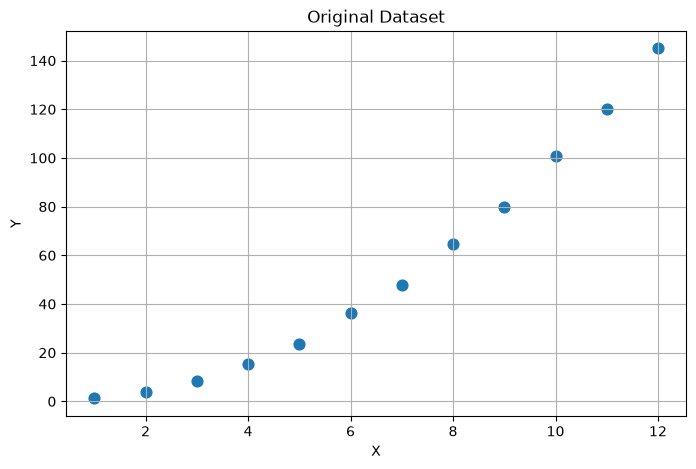

In [3]:
plt.figure(figsize =(8, 5))

plt.scatter(X, y, s=60)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Original Dataset")

plt.grid(True)
plt.show()

### Step 4: Demonstrate Underfitting
A degree-1 polynomial is equivalent to a linear regression model.

C:\Users\soham\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
<ipython-input-1-8dac966b74c6>:29: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show ()


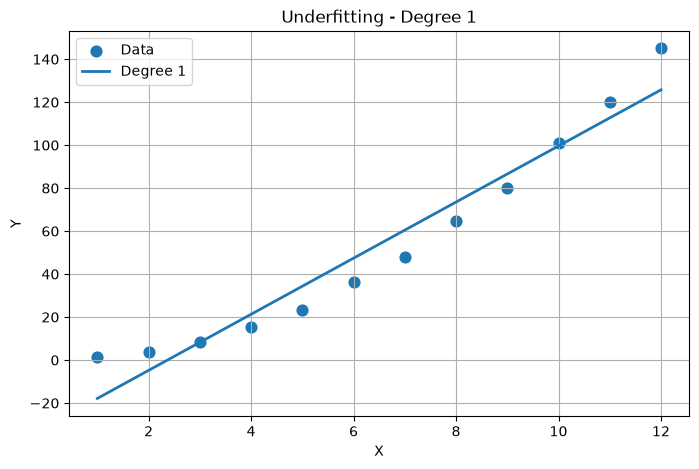

In [4]:
model_underfit = Pipeline ([
    ("poly", PolynomialFeatures(degree =1)),
    ("linear", LinearRegression ())
])

model_underfit.fit(X, y)

x_plot = np.linspace (1, 12, 300).reshape(-1, 1)

y_pred_underfit = model_underfit.predict(x_plot)

plt.figure(figsize =(8, 5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot ,
    y_pred_underfit ,
    linewidth =2,
    label="Degree 1"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Underfitting - Degree 1")

plt.legend ()
plt.grid(True)
plt.show ()

### Step 5: Demonstrate a Good Fit
Now use a degree-2 polynomial.

C:\Users\soham\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
<ipython-input-1-729482adb03e>:27: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show ()


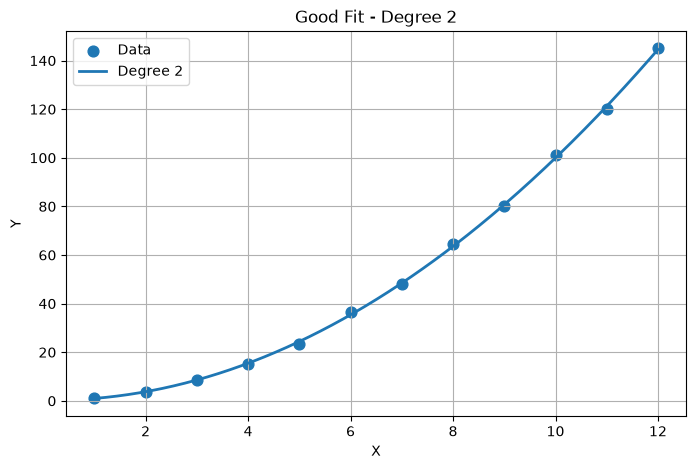

In [5]:
model_good = Pipeline ([
    ("poly", PolynomialFeatures(degree =2)),
    ("linear", LinearRegression ())
])

model_good.fit(X, y)

y_pred_good = model_good.predict(x_plot)

plt.figure(figsize =(8, 5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot ,
    y_pred_good ,
    linewidth =2,
    label="Degree 2"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Good Fit - Degree 2")

plt.legend ()
plt.grid(True)
plt.show ()

### Step 6: Demonstrate Overfitting
Now increase the model complexity.

C:\Users\soham\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
<ipython-input-1-26885dd6fb6b>:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show ()


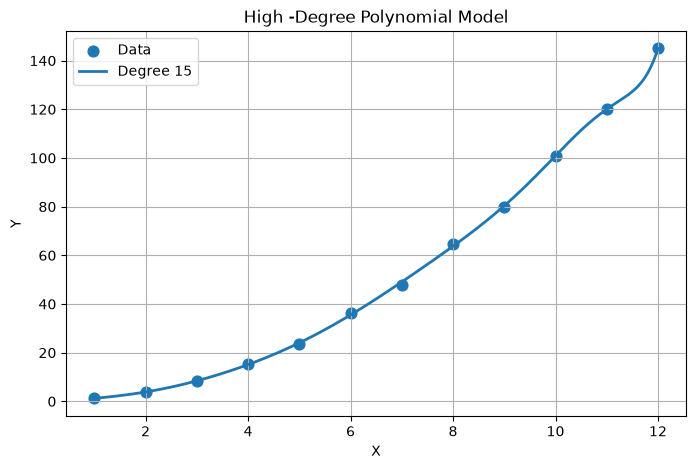

In [6]:
model_overfit = Pipeline ([
    ("poly", PolynomialFeatures(degree =15)),
    ("scale", StandardScaler ()),
    ("linear", LinearRegression ())
])

model_overfit.fit(X, y)

y_pred_overfit = model_overfit.predict(x_plot)

plt.figure(figsize =(8, 5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot ,
    y_pred_overfit ,
    linewidth =2,
    label="Degree 15"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("High -Degree Polynomial Model")

plt.legend ()
plt.grid(True)
plt.show ()

### Step 7: Apply Ridge Regularization
Ridge regularization is applied to the high-degree polynomial model.

C:\Users\soham\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
<ipython-input-1-40439770c4d4>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show ()


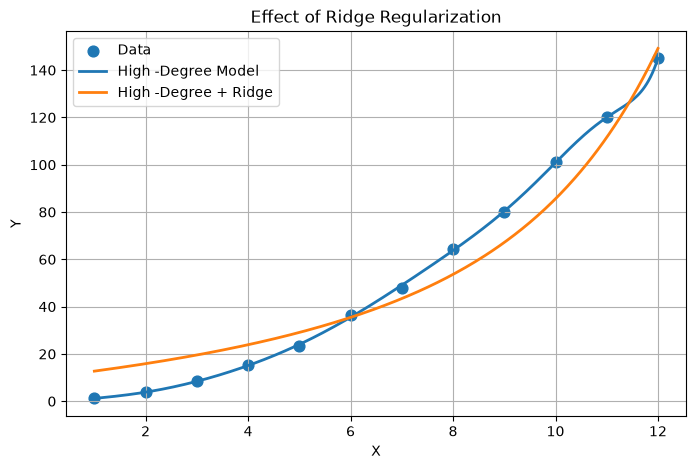

In [7]:
ridge_model = Pipeline ([
    ("poly", PolynomialFeatures(degree =15)),
    ("scale", StandardScaler ()),
    ("ridge", Ridge(alpha =10))
])

ridge_model.fit(X, y)

y_pred_ridge = ridge_model.predict(x_plot)

plt.figure(figsize =(8, 5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot ,
    y_pred_overfit ,
    linewidth =2,
    label="High -Degree Model"
)

plt.plot(
    x_plot ,
    y_pred_ridge ,
    linewidth =2,
    label="High -Degree + Ridge"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Effect of Ridge Regularization")

plt.legend ()
plt.grid(True)
plt.show ()

### Step 8: Apply Lasso Regularization
Lasso regularization is applied to the high-degree polynomial model.

C:\Users\soham\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
<ipython-input-1-fc6e07fa534c>:35: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show ()


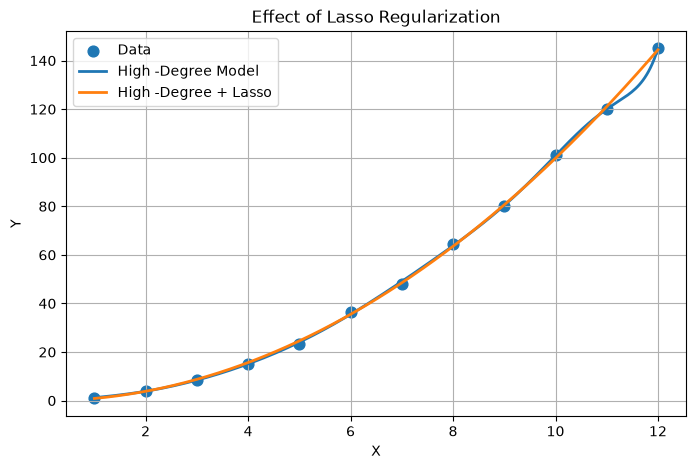

In [8]:
lasso_model = Pipeline ([
    ("poly", PolynomialFeatures(degree =15)),
    ("scale", StandardScaler ()),
    ("lasso", Lasso(alpha =0.1, max_iter =100000))
])

lasso_model.fit(X, y)

y_pred_lasso = lasso_model.predict(x_plot)

plt.figure(figsize =(8, 5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot ,
    y_pred_overfit ,
    linewidth =2,
    label="High -Degree Model"
)

plt.plot(
    x_plot ,
    y_pred_lasso ,
    linewidth =2,
    label="High -Degree + Lasso"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Effect of Lasso Regularization")

plt.legend ()
plt.grid(True)
plt.show ()

### Step 9: Compare All Models

<ipython-input-1-50d6a3b6729d>:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show ()


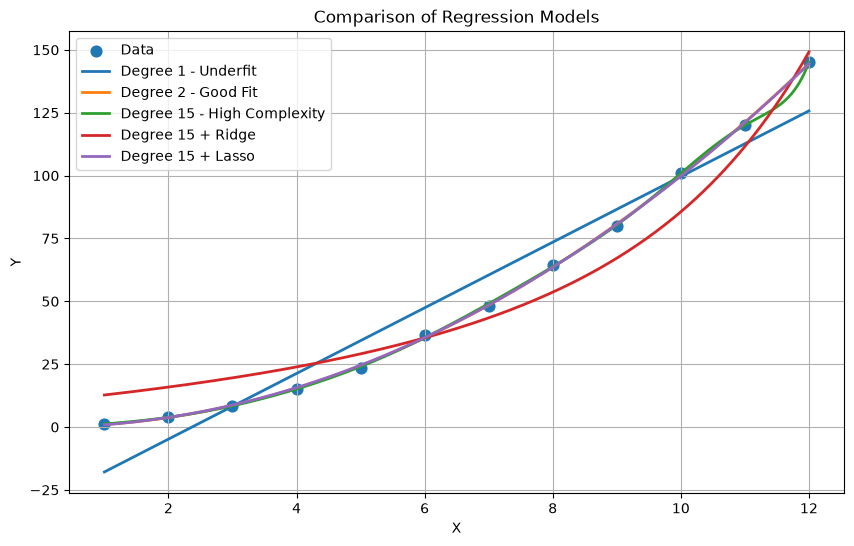

In [9]:
plt.figure(figsize =(10, 6))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot ,
    y_pred_underfit ,
    linewidth =2,
    label="Degree 1 - Underfit"
)

plt.plot(
    x_plot ,
    y_pred_good ,
    linewidth =2,
    label="Degree 2 - Good Fit"
)

plt.plot(
    x_plot ,
    y_pred_overfit ,
    linewidth =2,
    label="Degree 15 - High Complexity"
)

plt.plot(
    x_plot ,
    y_pred_ridge ,
    linewidth =2,
    label="Degree 15 + Ridge"
)

plt.plot(
    x_plot ,
    y_pred_lasso ,
    linewidth =2,
    label="Degree 15 + Lasso"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Comparison of Regression Models")

plt.legend ()
plt.grid(True)
plt.show ()

### Step 10: Compare Model Performance

In [10]:
models = {
    "Degree 1": model_underfit ,
    "Degree 2": model_good ,
    "Degree 15": model_overfit ,
    "Degree 15 + Ridge": ridge_model ,
    "Degree 15 + Lasso": lasso_model
}

results = []

for name , model in models.items ():
    prediction = model.predict(X)
    mse = mean_squared_error (y, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, prediction)
    results.append ([
        name ,
        mse ,
        rmse ,
        r2
    ])

results_df = pd.DataFrame(
    results ,
    columns =["Model", "MSE", "RMSE", "R2"]
)

print(results_df)

               Model         MSE       RMSE        R2
0           Degree 1  118.170101  10.870607  0.945012
1           Degree 2    0.547239   0.739756  0.999745
2          Degree 15    0.260094   0.509994  0.999879
3  Degree 15 + Ridge   94.898571   9.741590  0.955841
4  Degree 15 + Lasso    0.580480   0.761893  0.999730


### Step 11: Study the Effect of Different Ridge Values
Students can experiment with different regularization strengths.

In [11]:
alphas = [0.01 , 0.1, 1, 10, 100]

for alpha in alphas:
    ridge = Pipeline ([
        ("poly", PolynomialFeatures(degree =15)),
        ("scale", StandardScaler ()),
        ("ridge", Ridge(alpha=alpha))
    ])
    ridge.fit(X, y)
    prediction = ridge.predict(X)
    mse = mean_squared_error (y, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y, prediction)
    print(
        "Alpha:", alpha ,
        "MSE:", round(mse , 4),
        "RMSE:", round(rmse , 4),
        "R2:", round(r2 , 4)
    )

Alpha: 0.01 MSE: 0.5809 RMSE: 0.7622 R2: 0.9997
Alpha: 0.1 MSE: 1.6015 RMSE: 1.2655 R2: 0.9993
Alpha: 1 MSE: 5.7529 RMSE: 2.3985 R2: 0.9973
Alpha: 10 MSE: 94.8986 RMSE: 9.7416 R2: 0.9558
Alpha: 100 MSE: 589.7632 RMSE: 24.285 R2: 0.7256
